In [1]:
import pandas as pd
import os
import numpy as np
print(os.getcwd())

/Users/yoonwogud/Desktop/Git/DeepLearning/Part3


In [2]:
df = pd.read_csv('./sentence_tag.csv')
df.head()
df.shape

(2180, 5)

# Bag-of-Word(Bow) 빈도 벡터화
- 텍스트에서 출현한 토큰의 **빈도**로 벡터를 표현

빈도 벡터화는 `sklearn`의 `CountVectorizer`를 이용하여 구현합니다
- `max_df`: 해당 확률 이상으로 빈도가 많은 토큰을 제외
- `min_df`: 해당 확률 이하로 빈도가 적은 토큰을 제외

`CounterVectorizer`에는 `fit`함수에 문장 목록을 넣어 정보를 입력합니다. 이때 문장에서 띄어쓰기를 기준으로 토큰화하고 사전을 만드므로 미리 필요한 전처리를 진행해주어야 합니다.

In [3]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# 각 행을 하나의 문서로 봄
# 90% 이상으로 빈도가 많은 토큰을 제외, 2150개의 문서 중에서 90%의 문서에서 발견시
# 전체 문서에서 10개 이하로 빈도가 적은 토큰을 제외. 즉 2150개의 행에서 10개 이하 문서에서 발견시
# 정수로 주면 개수로 받고, 실수로 주면 비율로 받음
cvec = CountVectorizer(max_df=0.9, min_df=10)
cvec.fit(df['text_tag']) # 토큰생성(띄어쓰기 기반)

tokens = cvec.get_feature_names_out()   # 토큰 목록 확인
names = cvec.vocabulary_                # 토큰 사전 확인

print(len(tokens))
print(tokens)
print("\n")
print(names)

442
['가격' '가격대' '가능' '가로' '가로길이' '가성' '가운데' '가을' '가족' '감기' '감사' '감안' '강추' '개별'
 '개봉' '개선' '개인' '걱정' '검색' '검수' '검정' '겨울' '결과' '결론' '경우' '계절' '고객' '고급'
 '고무줄' '고민' '고정' '고집' '고학년' '공간' '공기' '광고' '광대' '교체' '교환' '구매' '구입' '구조'
 '귀걸이' '그거' '그것' '그날' '그동안' '그레' '그레이' '금액' '기능' '기대' '기미' '기본' '기분' '기존'
 '기준' '길이' '나리' '나머지' '나중' '날씨' '남성' '남아' '남자' '남편' '낭비' '낱개' '냄새' '넙대'
 '네이버' '노란색' '느낌' '니스' '다양' '다운' '다음' '다행' '단점' '답변' '당황' '대량' '대부분' '대비'
 '대신' '대체' '대형' '더위' '덕분' '데이즈' '데일리' '도움' '도착' '도톰' '독감' '동생' '동안' '동일'
 '두께' '득템' '디럭스' '디자인' '딸기' '딸아이' '라방' '라이브' '라이트' '라인' '라지' '럭스' '레몬'
 '레몬색' '레이' '리뷰' '리색' '마감' '마음' '마지막' '만족' '말씀' '머리' '먼지' '메이크업' '며칠' '면적'
 '모델' '모양' '무엇' '묶음' '문의' '문제' '물건' '미디' '미세먼지' '미스' '밀착' '바이러스' '박스'
 '반신반의' '반품' '발견' '밝은색' '방송' '방울' '배송' '밴드' '번창' '벌크' '베이지' '보관' '보리' '보통'
 '보풀' '본드' '본인' '볼살' '봉지' '봉투' '부담' '부리' '부모' '부분' '부위' '부직포' '부탁' '분홍'
 '불량' '불량품' '불안' '불편' '브랜드' '브리즈' '브이' '블랙' '비교' '비닐' '비염' '사고' '사람' '사용'
 '사이' '사이즈' '사진' '살구색' '살색' '상세' '상자' '상태' '상품'

> `get_feature_names_out`함수를 통해 텍스트 뭉치에 포함된 토큰 목록을 확인합니다.

> `vocabulary_`변수를 통해 텍스트 뭉치에 포함된 토큰의 사전을 확인합니다.

> `vocabulary_` : 학습(fit) 후 만들어진 “단어 → 인덱스” 딕셔너리

`fit`가 진행된 `CountVectorizer`에서 `transform`함수를 활용하여 문장목록을 벡터 목록으로 변환 가능합니다.

In [4]:
text = df.loc[3, 'text_tag']
text


'라이브 방송 언니 가로 사이즈 저 사진 부분 밀착 코 와이어 블로그 리뷰 길거리 사람 잘못 코 부분 최대한 콧등 소용 콧등 부분 밀착 생각 합 중형 끈 색상 촉감 얼굴 안감 공장 냄새 자체 디자인 중형 사이즈 바램'

In [27]:
# fit으로 전체 문장을 띄어쓰기 기준으로 나누고
# transform으로 한 문장을 sparse matrix 행렬로 바꿈
# {'배송': 0, '좋아요': 1, '빠름': 2, '포장': 3, '예쁘다': 4}
# (0, 3)    1       0번째 문서에서 3번 인덱스가 1번 나왔다.
# (0, 4)    1
X = cvec.transform([text])
print(X)

# [[1, 0, 0, 0, 1, 0]] 리스트로 바꾸면이렇게됨
x = X.toarray()

print(x.shape)
print(x)
# 1번 출현한 것은 최소 1이니 0이 아닌것 출력하기
print(f"출현 토큰 번호 확인 {np.nonzero(x[0])}")

  (np.int32(0), np.int32(3))	1
  (np.int32(0), np.int32(68))	1
  (np.int32(0), np.int32(101))	1
  (np.int32(0), np.int32(105))	1
  (np.int32(0), np.int32(113))	1
  (np.int32(0), np.int32(135))	2
  (np.int32(0), np.int32(142))	1
  (np.int32(0), np.int32(161))	3
  (np.int32(0), np.int32(178))	1
  (np.int32(0), np.int32(181))	2
  (np.int32(0), np.int32(182))	1
  (np.int32(0), np.int32(193))	1
  (np.int32(0), np.int32(196))	1
  (np.int32(0), np.int32(249))	1
  (np.int32(0), np.int32(262))	1
  (np.int32(0), np.int32(263))	1
  (np.int32(0), np.int32(324))	1
  (np.int32(0), np.int32(345))	2
  (np.int32(0), np.int32(380))	2
(1, 442)
[[0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0
  0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 1 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1

In [29]:
# 이제 전체를 트랜스포함
X  = cvec.transform(df['text_tag'])
# 리스트로 바꿔서 출력하고
# 여기에선 여러행을 인코딩 시키니깐 문서개수만큼 행이 나옴, 즉 toarray를 해도 sparse matrix임
x = X.toarray()

print(x.shape)
# 2180개의 문서에 442개의 단어

(2180, 442)


In [30]:
csum = np.sum(x, axis=0)# column
# 열 방향으로 합을 구함. 모든 문서에서 각 단어가 몇번씩 등장했는가.
print(csum)
print(csum.shape)
# 그러면 다 합치니깐 1행의 442개의 형태가 나올것임

[ 603   13   47   90   25   79   11   45   76   14   83   11   43  126
   34   18   97  116   11   44   44  117   12   11   41   21   12   40
   22  169   25   12   12   40   16   19  115   11   39 1444  259   15
   16   14   22   17   14   20  192   16   20   69   16   24   73  136
   30  202   14   16   18   51   69   11   97  195   11   45  140   10
   25   16  391   51   37   29  111   24   26   16   24   24   15   67
   27   14  944   12   12   15  102   16   38   12   11   26   20   26
  231   10 1041  154   10   17  186  272  298  129   74   36   19   16
   17  112   11   29  166   16  421   19   12   22   11   13   28   16
  110   75   25   19   54   17   17   37   11  118   12   39   11   73
   22   12  217   19  259   34   15  153  604   18   11  193   68   15
   10   30   24   37   74   21   14  500   18   23   16   15  219   14
   23  228   99  530   11  142  215   69   11   10  114  805   28 1467
  284   29   15   20   15   25  106  219  109  135   35  827   10   16
  334 

In [8]:
# 빈도 순으로 정렬
# np.argsort(csum) 은
# → [1, 3, 0, 2]
# 즉, 가장 작은 값부터 인덱스를 정렬한 배열을 줘.
# (5가 제일 작으니까 인덱스 1이 맨 앞)
csort_ind = np.argsort(csum)[::-1] # 역순으로 정렬
for i in csort_ind[:10]:
    print(f'{tokens[i]} : {csum[i]}')
    # 토큰에는 '배송', '좋아요'      csum에는 등장횟수

사이즈 : 1467
구매 : 1444
얼굴 : 1415
중형 : 1255
디럭스 : 1041
대형 : 944
핑크 : 925
색상 : 827
사용 : 805
에코 : 613


## TF-IDF 벡터화

**TF-IDF** 는 단어의 빈도인 TF에 단어의 역문서 빈도인 IDF(희소성)을 곱한값으로 단어의 중요도를 나타내는 수치로 활용 가능합니다. 이런 TF-IDF값으로 문장을 벡터로 나타내는 것이 TF-IDF벡터화입니다.


TF-IDF 벡터는 `sklearn`모듈의 `TfidVectorizer`를 이용하여 간단하게 구현할 수 있습니다. 활용방법은 `CountVectorizer`와 동일합니다.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfvec = TfidfVectorizer(max_df=0.9, min_df=10)
tfvec.fit(df['text_tag'])

tokens = tfvec.get_feature_names_out()
print(tokens)

names = tfvec.vocabulary_
print(names)
#희소성이 추가 되어서 위의 거랑은 좀 다름

['가격' '가격대' '가능' '가로' '가로길이' '가성' '가운데' '가을' '가족' '감기' '감사' '감안' '강추' '개별'
 '개봉' '개선' '개인' '걱정' '검색' '검수' '검정' '겨울' '결과' '결론' '경우' '계절' '고객' '고급'
 '고무줄' '고민' '고정' '고집' '고학년' '공간' '공기' '광고' '광대' '교체' '교환' '구매' '구입' '구조'
 '귀걸이' '그거' '그것' '그날' '그동안' '그레' '그레이' '금액' '기능' '기대' '기미' '기본' '기분' '기존'
 '기준' '길이' '나리' '나머지' '나중' '날씨' '남성' '남아' '남자' '남편' '낭비' '낱개' '냄새' '넙대'
 '네이버' '노란색' '느낌' '니스' '다양' '다운' '다음' '다행' '단점' '답변' '당황' '대량' '대부분' '대비'
 '대신' '대체' '대형' '더위' '덕분' '데이즈' '데일리' '도움' '도착' '도톰' '독감' '동생' '동안' '동일'
 '두께' '득템' '디럭스' '디자인' '딸기' '딸아이' '라방' '라이브' '라이트' '라인' '라지' '럭스' '레몬'
 '레몬색' '레이' '리뷰' '리색' '마감' '마음' '마지막' '만족' '말씀' '머리' '먼지' '메이크업' '며칠' '면적'
 '모델' '모양' '무엇' '묶음' '문의' '문제' '물건' '미디' '미세먼지' '미스' '밀착' '바이러스' '박스'
 '반신반의' '반품' '발견' '밝은색' '방송' '방울' '배송' '밴드' '번창' '벌크' '베이지' '보관' '보리' '보통'
 '보풀' '본드' '본인' '볼살' '봉지' '봉투' '부담' '부리' '부모' '부분' '부위' '부직포' '부탁' '분홍'
 '불량' '불량품' '불안' '불편' '브랜드' '브리즈' '브이' '블랙' '비교' '비닐' '비염' '사고' '사람' '사용'
 '사이' '사이즈' '사진' '살구색' '살색' '상세' '상자' '상태' '상품' '새부

In [10]:
X = tfvec.transform(df['text']) # 인코딩
x = X.toarray()
print(x.shape)

print(np.nonzero(x[0]))
# 이건 똑같이 한 문장 인코딩한거임

(2180, 442)
(array([  7,  21,  70,  86, 147, 151, 174, 179, 181, 189, 248, 256, 263,
       273, 319, 358, 367, 383, 402, 414, 432]),)


In [11]:
x = tfvec.transform(df['text_tag'])
x = x.toarray()
print(x.shape)


# Countervectorizer에서는 단어의 빈도만 보기 때문에 sum으로 했는데
# 평균으로 하면 문서 수에 관계없이 가능
tfmean = np.mean(x, axis=0)

# 이 수치들을 역으로 정렬해서
# 단어와 수치들을 상위 10개만 나타내라
tfsort_ind = np.argsort(tfmean)[::-1]
for i in tfsort_ind[:10]:
    print(f'{tokens[i]} : {tfmean[i]}')

(2180, 442)
사이즈 : 0.07475292334151314
구매 : 0.07180038270297039
얼굴 : 0.07060486181341881
중형 : 0.06690076212864184
대형 : 0.05752251386284688
핑크 : 0.055548233075104134
디럭스 : 0.05536429348509769
색상 : 0.051958085271497756
사용 : 0.04976534938989779
가격 : 0.04115382666685914


# 텍스트 임베딩

BoW, TF-IDF에서는 단어의 순서, 주변단어 등 문맥에 대한 정보가 제대로 반영되지 않습니다. 즉 단어의 문백적인 의미를 파악할 수 없다는 문제가 존재합니다.

임베딩 기법은 단어를 저차원 벡터 공간에 매핑하여 단어간 의미적 유사도를 학습하여 벡터의 값을 설정합니다.
- **단어 간의 의미 관계 학습**: 의미가 유사하거나 관련이 있는 단어들이 벡터 공간에서 가깝게 배치되어 모델이 의미적 맥락을 더 잘 이해함
- **차원 축소 및 일반화**: 저차원 벡터에 정보를 압축하여 메모리 사용량을 줄이고, 모델 학습시 일반화에 유리

임베딩은 크게 단어 임베딩과 문장 임베딩으로 나뉩니다

## Word2Vec 단어 임베딩

Word2Vec모델은 키워드 간의 유사도를 학습하여 단어 임베딩을 만드는 대표적인 모델입니다.

`gensim`라이브러리를 활용하여 `Word2Vec`모델을 구성하고 학습합니다

In [12]:
# import shutil
# import matplotlib as mpl

# # 폰트 캐시 파일을 수동으로 삭제 -- !!!조심!!! 한글이 깨질경우만 실행
# font_cache_dir = mpl.get_cachedir()
# shutil.rmtree(font_cache_dir)

import matplotlib as mpl
import shutil

shutil.rmtree(mpl.get_cachedir(), ignore_errors=True)

Word2Vec는 토큰화된 문장 목록 데이터를 통해 학습이 가능합니다. 기존 전처리된 데이터를 토큰화하여 목록으로 만듭니다.

In [13]:
data = pd.read_csv('./sentence_tag.csv')
sentences = data['text_tag'].apply(lambda x: x.split()).to_list()
print(sentences[:10])

[['새부리', '검색', '네이버', '랭킹', '상위', '가격', '호기심', '핑크', '베이지', '색상', '서요', '화이트', '블랙', '핑크', '계열', '무엇', '가격', '메리트', '장바구니', '때', '결제', '하루', '라이브', '타이밍', '운', '아침', '반', '라방', '전', '성공', '당일', '출고', '담날', '봄', '여름', '핑크', '가을', '겨울', '톤', '핑크', '핑크', '베이지', '톤', '맘', '후기', '중형', '일반', '대형', '사이즈', '중형', '나', '남편', '보통', '얼굴', '크기', '남성', '중형', '폭', '얼굴', '전체', '세로', '부족', '사진', '미', '밋', '대형', '아이', '어른', '비교', '사이즈', '벌크', '포장', '때', '불량', '사용', '후기', '일', '가성', '추천'], ['컬러', '컬러', '벌크', '포장', '퀄리티', '내심', '제', '생각', '일치', '동호', '런', '칭', '방송', '때', '신상', '포', '배', '너', '오픈', '구매', '포장', '일', '에코', '브리즈', '무광', '유광', '구성', '나중', '라이트', '실버', '구매', '색상', '요거', '러블리', '두께', '에코', '프로', '스타일', '핏', '클래식', '디럭스', '중구', '조임', '사진', '체감', '숨', '귀', '끈', '두말', '잔소리', '안감', '스펀', '본드', '저', '에코', '프로', '만족', '폭', '닥', '폭', '닥', '부직포', '느낌', '사이즈', '제', '중형', '여유', '저', '참고', '귀', '끈', '클립', '사용', '얼굴', '살', '옆', '부분', '라인', '핏', '측면', '귀', '옆', '주현', '말씀', '압착', '처음', '귀', '끈', '귀', '옆', '귀'

### Word2Vec 학습하기

Word2Vec는 같이 자주 등장하는 단어들을 학습하기 위해 중심단어에서 설정한 윈도우 크기안에 들어오는 단어를 주변단어로 설정하여 학습합니다.



모델에 입력된 단어들은 임베딩 행렬(Embedding Matrix)을 거처 임베딩 벡터로 바뀌고 벡터는 주변단어와의 유사도가 높은 값으로 학습이 진행됩니다.

*임베딩 행렬 예시*

이때 대표적인 학습 알고리즘으로 **Skip-gram**과 **CBOW**을 활용합니다.

- **Skip-gram**: 중심단어로 주변단어를 예측하는 방식
  - 학습시 입력이 중심단어 라벨이 주변단어
  - 희소 데이터(드물게 등장하는 단어)를 더 잘 학습
  - 계산 비용이 높음

- **CBOW(Continous Bag of Words)**
  - 학습시 입력이 주변단어 라벨이 중심단어
  - 계산비용이 낮고 빠르게 학습

CBOW 예시

In [65]:
from gensim.models import Word2Vec
model = Word2Vec(sentences, vector_size=100, window=5, min_count=5, workers=4, sg=1)# 1skipgram, 0CBOW

# 벡터 사이즈는 100으로 한다. [0.01, 0.123, 0.341, ...,]
             #ex) cat 동물관련, 귀여움관련, 애완동물 관련, 작은 크기 관련..
# 최소 5개는 나와야지 학습에 사용한다.

In [66]:
# 모델에는 단어의 벡터 정보가 들어가있음

# model
# Word2Vec 전체 모델 객체. 학습 설정, 트레이닝 파라미터, 학습 로직 등 다 포함돼 있어.


# model.wv
# 학습 완료된 단어 벡터(Word Vectors) 만 저장된 부분.


# model.WordVector.index_to_key = 모델이 학습한 모든 단어 목록 리스트로 내기
keywords = model.wv.index_to_key
keywords[:10]

['사이즈', '구매', '얼굴', '중형', '디럭스', '대형', '핑크', '색상', '사용', '때']

#### 유사 키워드 추출

- most_similar()를 통해 코사인 유사도를 계산하여 가까운 상위 키워드 추출


In [52]:
# 유사한 단어 추출

keyword='남편'
# '사이즈'의 벡터를 사용해서 의미적으로 가까운 단어를 찾게 돼.
similar_words = model.wv.most_similar(keyword, topn=5)
similar_words

# for word, similarity in similar_words:
#     print(f'{word}: {similarity:.4f}')


[('제', 0.998919665813446),
 ('남자', 0.9987723231315613),
 ('저', 0.9987456798553467),
 ('라지', 0.9986750483512878),
 ('참고', 0.9986646175384521)]

In [53]:
# 두개의 키워드를 사용
keywords = ['사이즈', '사용']
similar_words = model.wv.most_similar(positive=keywords, topn=20)
similar_words

[('일반', 0.9986938238143921),
 ('크기', 0.9985824227333069),
 ('소형', 0.9985414147377014),
 ('남성', 0.9984704852104187),
 ('참고', 0.9984555840492249),
 ('가로', 0.9983682632446289),
 ('여유', 0.9983645677566528),
 ('남자', 0.9982652068138123),
 ('남편', 0.9979866743087769),
 ('저', 0.9979685544967651),
 ('길이', 0.9977588057518005),
 ('고민', 0.9976611733436584),
 ('제', 0.9975327253341675),
 ('중소형', 0.9973814487457275),
 ('기존', 0.9972169399261475),
 ('평소', 0.9971449375152588),
 ('세로', 0.9970051646232605),
 ('대', 0.9969728589057922),
 ('광대', 0.9965646266937256),
 ('평균', 0.9965444207191467)]

In [54]:
# 부정 키워드 사용
keyword = '사이즈'
neg_key = '소두'
similar_words = model.wv.most_similar(keyword, negative=neg_key, topn=20)
similar_words
# 이렇게 나오는 숫자들은  -1<= similarity <= 1, 벡터들 사이의 각도를 이용한 코사인 유사도
#          ↑ "동생"
#          |
#          | 0.95 (거의 같은 방향)
#          |
# "keyword" ●────────→ "무관한 단어" (0.1 근처)


[('에코', 0.2621650695800781),
 ('브리즈', 0.24435128271579742),
 ('중형', 0.23103496432304382),
 ('대형', 0.21146494150161743),
 ('디럭스', 0.18887358903884888),
 ('프로', 0.15077613294124603),
 ('플러스', 0.10563343018293381),
 ('보통', 0.09390836954116821),
 ('여성', 0.08569835871458054),
 ('여자', 0.08090850710868835),
 ('차이', 0.07993683964014053),
 ('얼굴', 0.0765918418765068),
 ('성인', 0.05776580795645714),
 ('데일리', 0.05761042237281799),
 ('크기', 0.05596035718917847),
 ('비교', 0.05181529000401497),
 ('세로', 0.04632841795682907),
 ('일반', 0.042159467935562134),
 ('남성', 0.032608937472105026),
 ('남자', 0.008753829635679722)]

### 유사 키워드 시각화(응용)

실제 임베딩 벡터는 매우 큰 차원을 가지기 때문에 그래프로 시각화하기 어렵습니다.
하지만 PCA로 차원추소를 한다면 간단한 산점도 그래프로 시각화가 가능해집니다.



In [55]:
# 사이즈에 해당하는 벡터 정보를 보려면 이렇게
keyword='사이즈'
model.wv[keyword]

array([-1.80383131e-01,  2.74938554e-01,  1.49701983e-01,  2.64221430e-02,
        1.73712313e-01, -5.34948051e-01,  3.49048913e-01,  7.05338478e-01,
       -1.62506267e-01, -1.87124163e-01, -2.86869943e-01, -5.11076510e-01,
       -5.27243654e-04,  7.44697750e-02,  1.18439063e-01, -1.99382737e-01,
        4.49339263e-02, -1.49339691e-01, -1.79279998e-01, -6.07010663e-01,
        6.34149387e-02, -3.15499492e-02,  1.27399594e-01, -1.56414449e-01,
       -2.71410525e-01, -5.13700256e-03, -8.61887857e-02, -1.77658707e-01,
       -2.90453970e-01,  6.77494705e-02,  2.97833771e-01, -4.27318029e-02,
        1.56105027e-01, -3.42826396e-01, -1.17186479e-01,  4.20088977e-01,
       -9.13360994e-03, -2.99506545e-01, -1.06916733e-01, -3.92497092e-01,
        3.91442515e-02, -1.87207520e-01, -1.50665030e-01,  7.18976632e-02,
        4.60503161e-01, -1.94001108e-01, -2.33149081e-01, -1.32913053e-01,
        3.20533872e-01,  2.01464549e-01,  2.55509317e-01, -2.10595220e-01,
        1.22796863e-01, -

In [56]:
keyword='사이즈'
# 상위 20개의 이름과 cos similarity
similar_words = model.wv.most_similar(keyword, topn=20)

# 사이즈 + 성인 + 라지 ...
words = [keyword] + [word for word, _ in similar_words]

# 사이즈 + 상위 20개 각각의 100차원 벡터 정보
vectors = [model.wv[word] for word in words]

# numpy 행렬로 만들기
np.array(vectors).shape

(21, 100)

#### PCA 차원 축소

`sklearn.decompostion`의 `PCA`를 활용하여 간단하게 PCA 차원 축소가 가능합니다
  - 데이터 분산(Variance)을 최대한 보존하는 방향벡터로 구현
  - 데이터 손실이 발생하긴 하지만 중요 정보는 최대한 유지

`n_components`인자에 남길 차원의 개수를 입력하여 축소합니다.

In [57]:
from sklearn.decomposition import PCA

# PCA로 2차원 변환
# 저 값도 elbow point로 최적을 찾아낼 수 있음
# 먼저 분산을 최소로 하는 축을 찾고 두번째로 그 축에 직교하는 축을 그어서 2차원으로 만듦
pca = PCA(n_components=2)
# 아까 vectors가 100개의 벡터니깐 == 100개의 column
# 이걸 2차원으로 줄이겠다.
reduced_vectors = pca.fit_transform(vectors)
reduced_vectors

array([[-0.0039154 ,  0.22594954],
       [-0.0018201 ,  0.09330691],
       [-0.23796139,  0.04342225],
       [-0.07093486,  0.05485138],
       [ 0.13045754,  0.04947499],
       [ 0.25677126,  0.16967775],
       [-0.06561255, -0.05292964],
       [ 0.14215679,  0.05438852],
       [-0.15188637,  0.04801783],
       [ 0.1439334 ,  0.0339979 ],
       [-0.38137286, -0.1646295 ],
       [-0.18492622,  0.46543289],
       [-0.04839034, -0.02610022],
       [ 0.07928437, -0.11962596],
       [ 0.01909476, -0.1336438 ],
       [ 0.30777194, -0.05642532],
       [ 0.34051044, -0.08804584],
       [ 0.18000095, -0.12497732],
       [-0.33248302, -0.0810942 ],
       [ 0.0989136 , -0.16477314],
       [-0.21959194, -0.22627501]])

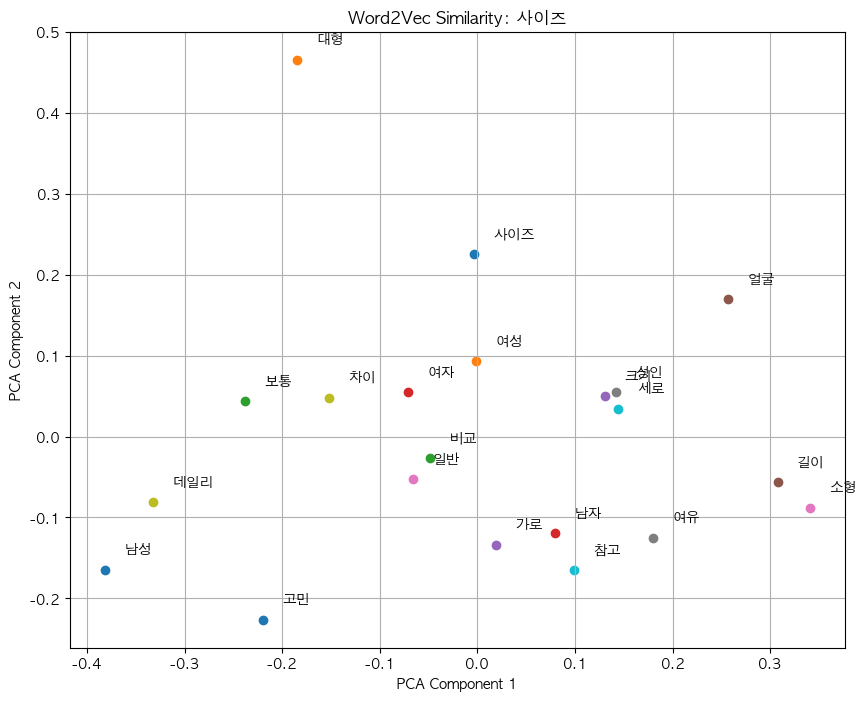

In [58]:
import matplotlib.pyplot as plt

# 설치된 나눔고딕 폰트를 불러와 Matplotlib의 기본 폰트로 설정
plt.rc('font', family='AppleGothic')
# 음수 부호 사용
plt.rcParams['axes.unicode_minus'] = False

# 산점도 그리기
plt.figure(figsize=(10, 8))

for i, word in enumerate(words):
    plt.scatter(reduced_vectors[i, 0], reduced_vectors[i, 1])
    plt.annotate(word, (reduced_vectors[i, 0] + 0.02, reduced_vectors[i, 1] + 0.02))

plt.title(f"Word2Vec Similarity: {keyword}")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(True)
plt.show()

## FastText, Glove 단어 임베딩

기존 Word2Vec학습방식 문제점을 해결하기 위한 다양한 임베딩 모델이 등장하게 됩니다.

### FastText
FastText는 기본적으로 Word2Vec와 유사한 Skip-gram 또는 CBOW 구조를 학습 기반 모델로, 단어를 n-gram으로 분해하는 추가 과정이 들어가 임베딩의 성능을 높입니다.
- Subword(부분단어) 정보 반영
  - Word2Vec와 달리 단어를 여러개의 n-gram으로 나누어 각 n-gram 임베딩을 합산하여 최종 단어 벡터를 구성합니다.
  - 신조어, 희귀어, 띄어쓰기 오류, 형태 변화등이 있는 부분 단어의 벡터를 활용해 비교적 안정적인 임베딩을 얻을 수 있습니다.
- OOV(Out-of-Vocabulary)
  - 기존 Word2Vec는 학습 코퍼스에서 본적 없는 단어(OOV)에 대한 벡터가 정의되지 않으나, FastText는 서브워드 단위의 임베딩을 조합해 벡터를 생성할 수 있으므로 OOV에 대한 대응력이 향상됩니다.

### GloVe(Global Vectors for Word Representation)
GloVe는 Word2Vec처럼 예측 기반 접근이 아니라 전체 코퍼스에서 단어 쌍이 함께 등장하는 횟수(동시 발생빈도)를 집계하여 임베딩 학습을 합니다.
- 전역적 동시 발생 행렬(Co-occurrenc Matrix) 기반
- 전역 정보와 지역 정보 모두 활용
  - GloVe는 문서 전체 차원의 통계와 국소적인 맥락 정보를 모두 반영하여 단어 벡터를 학습합니다
- 희소 행렬처리를 위한 효율성
  - 대규모 단어 사전에서 동시 발생 행렬은 매우 커질수 있으므로, GloVe는 이를 효율적으로 학습하기 위한 비용함수를 정의하고 최적화 기법을 적용해 성능을 높입니다.


### FastText 학습하기

FastText는 단어를 n그램의 서브워드로 쪼개므로 최소 n과 최대 n을 설정해야 합니다.

    최소n: 3
    최대n: 5

    원단어: 안녕하세요
    3-gram: 안녕하, 녕하세, 하세요
    4-gram: 안녕하세, 녕하세요
    5-gram: 안녕하세

In [67]:
from gensim.models import FastText

# FastText 학습
fasttext_model = FastText(
    sentences,    # 학습 문장 세트
    vector_size=100,  # 임베딩 벡터 사이즈
    window=5,         # 윈도우 크기
    min_count=2,      # 최소 빈도
    min_n=2,          # n-gram 으로 쪼개질때 최소 글자(최소n)
    max_n=6,          # n-gram 으로 쪼개질때 최대 글자(최대n)
    workers=4,        # 사용 코어 개수
    sg=1,             # 1: Skip-gram, 0: CBOW
    epochs=50         # 전체 학습 반복 횟수
)

In [68]:
# 유사한 단어 추출
keyword = '통통'
similar_words = fasttext_model.wv.most_similar(keyword, topn=20)
similar_words

[('통', 0.8172781467437744),
 ('소짜', 0.7414935827255249),
 ('견질', 0.7089428305625916),
 ('소유자', 0.7023296356201172),
 ('한국', 0.6976521611213684),
 ('앞면', 0.6839397549629211),
 ('방중', 0.6814613342285156),
 ('대소', 0.6810053586959839),
 ('진짜', 0.6782612204551697),
 ('대', 0.6758501529693604),
 ('중고', 0.6687042713165283),
 ('중형', 0.6681909561157227),
 ('곰', 0.6643843650817871),
 ('공통', 0.6630797386169434),
 ('넉', 0.663045346736908),
 ('탐', 0.6593103408813477),
 ('중안', 0.6562619805335999),
 ('대두', 0.6547453999519348),
 ('맞음', 0.6537375450134277),
 ('옆길', 0.652363121509552)]